# Heart Disease Prediction

Can routine clinical measurements (age, chest-pain type, maximum heart rate, ST depression, etc.) predict whether a patient has heart disease?
This notebook compares four classifiers on the UCI Heart Disease dataset. Recall on the disease class matters most, because a missed diagnosis is costlier than a false alarm.

**Key finding before modelling:** 723 of the 1,025 rows are exact duplicates. Removing them leaves **302 unique patients**. Skipping this step lets duplicates leak between the train and test sets and inflates accuracy towards ~100%.

In [1]:
# ========================================
# 1. IMPORT LIBRARIES
# ========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)
import os
import warnings
warnings.filterwarnings('ignore')
os.makedirs('images', exist_ok=True)

## 1. Load data

In [2]:
# ========================================
# 2. LOAD DATASET
# ========================================
df = pd.read_csv('data/heart.csv')

print("="*50)
print("DATASET LOADED SUCCESSFULLY")
print("="*50)
print(f"\nDataset Shape: {df.shape}")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(f"\n")

DATASET LOADED SUCCESSFULLY

Dataset Shape: (1025, 14)
Rows: 1025, Columns: 14




## 2. First look

In [3]:
# ========================================
# 3. EDA
# ========================================
print("\n" + "="*50)
print("FIRST 5 ROWS")
print("="*50)
print(df.head())

print("\n" + "="*50)
print("DATASET INFO")
print("="*50)
print(df.info())

print("\n" + "="*50)
print("STATISTICAL SUMMARY")
print("="*50)
print(df.describe())

print("\n" + "="*50)
print("MISSING VALUES CHECK")
print("="*50)
print(df.isnull().sum())

print("\n" + "="*50)
print("TARGET VARIABLE DISTRIBUTION")
print("="*50)
print(df['target'].value_counts())


FIRST 5 ROWS
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non

In [4]:
# ========================================
# 4. SET STYLE
# ========================================
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 3. Duplicate check

The raw file has 1,025 rows, but most are copies of the same patients. If duplicates stay in, an identical record can land in both the train and test sets, and the model is rewarded for memorising rather than generalising.

In [5]:
# What happens if we DON'T remove duplicates?
Xd, yd = df.drop('target', axis=1), df['target']
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=42, stratify=yd)
seen = set(map(tuple, Xd_tr.values))
leaked = sum(tuple(r) in seen for r in Xd_te.values)
rf_leaky = RandomForestClassifier(random_state=42).fit(Xd_tr, yd_tr)
print(f"Test rows that also appear in train: {leaked} / {len(Xd_te)}")
print(f"Random Forest 'accuracy' with duplicates: {rf_leaky.score(Xd_te, yd_te):.3f}  <- misleading")

Test rows that also appear in train: 202 / 205
Random Forest 'accuracy' with duplicates: 1.000  <- misleading


In [6]:
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates} of {len(df)}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Unique patients: {df.shape[0]}")
print(df['target'].value_counts())

Duplicate rows: 723 of 1025
Unique patients: 302
target
1    164
0    138
Name: count, dtype: int64


## 4. Exploratory analysis (on the de-duplicated data)

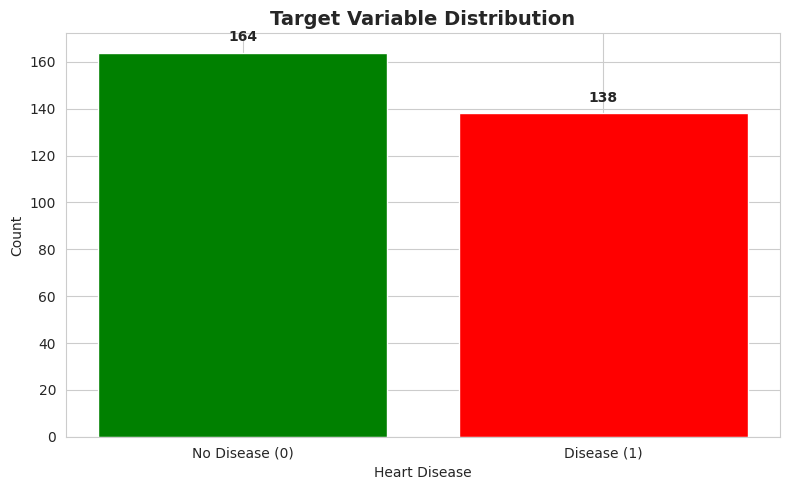

In [7]:
# ========================================
# 6. EXPLORATORY DATA ANALYSIS (EDA)
# ========================================

# 6.1 Target Distribution
plt.figure(figsize=(8, 5))
target_counts = df['target'].value_counts()
plt.bar(['No Disease (0)', 'Disease (1)'], target_counts.values, color=['green', 'red'])
plt.title('Target Variable Distribution', fontsize=14, fontweight='bold')
plt.ylabel('Count')
plt.xlabel('Heart Disease')
for i, v in enumerate(target_counts.values):
    plt.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('images/target_distribution.png', dpi=300)
plt.show()

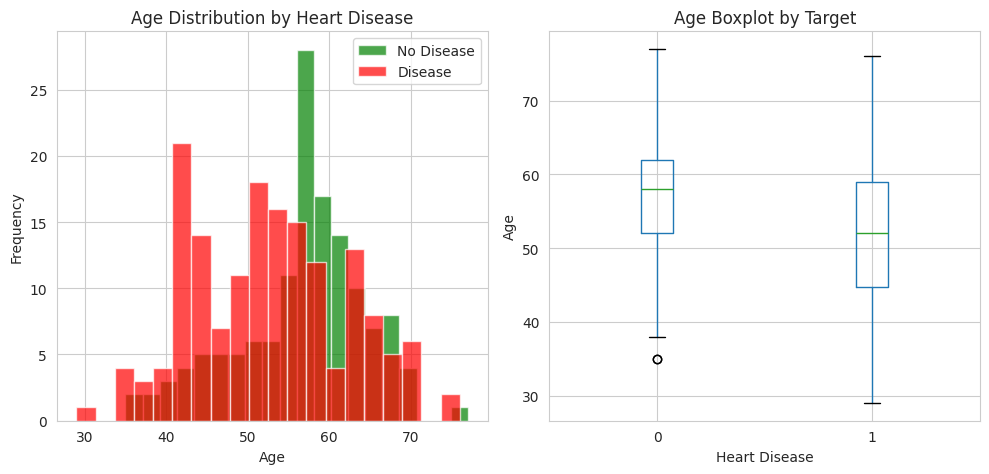

In [8]:
# 6.2 Age Distribution by Target
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(df[df['target']==0]['age'], bins=20, alpha=0.7, label='No Disease', color='green')
plt.hist(df[df['target']==1]['age'], bins=20, alpha=0.7, label='Disease', color='red')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution by Heart Disease')
plt.legend()

plt.subplot(1, 2, 2)
df.boxplot(column='age', by='target', ax=plt.gca())
plt.suptitle('')
plt.title('Age Boxplot by Target')
plt.xlabel('Heart Disease')
plt.ylabel('Age')
plt.tight_layout()
plt.savefig('images/age_analysis.png', dpi=300)
plt.show()

Correlations: chest-pain type (`cp`), max heart rate (`thalach`) and slope correlate positively with disease; exercise-induced angina (`exang`), ST depression (`oldpeak`), number of vessels (`ca`) and `thal` correlate negatively.

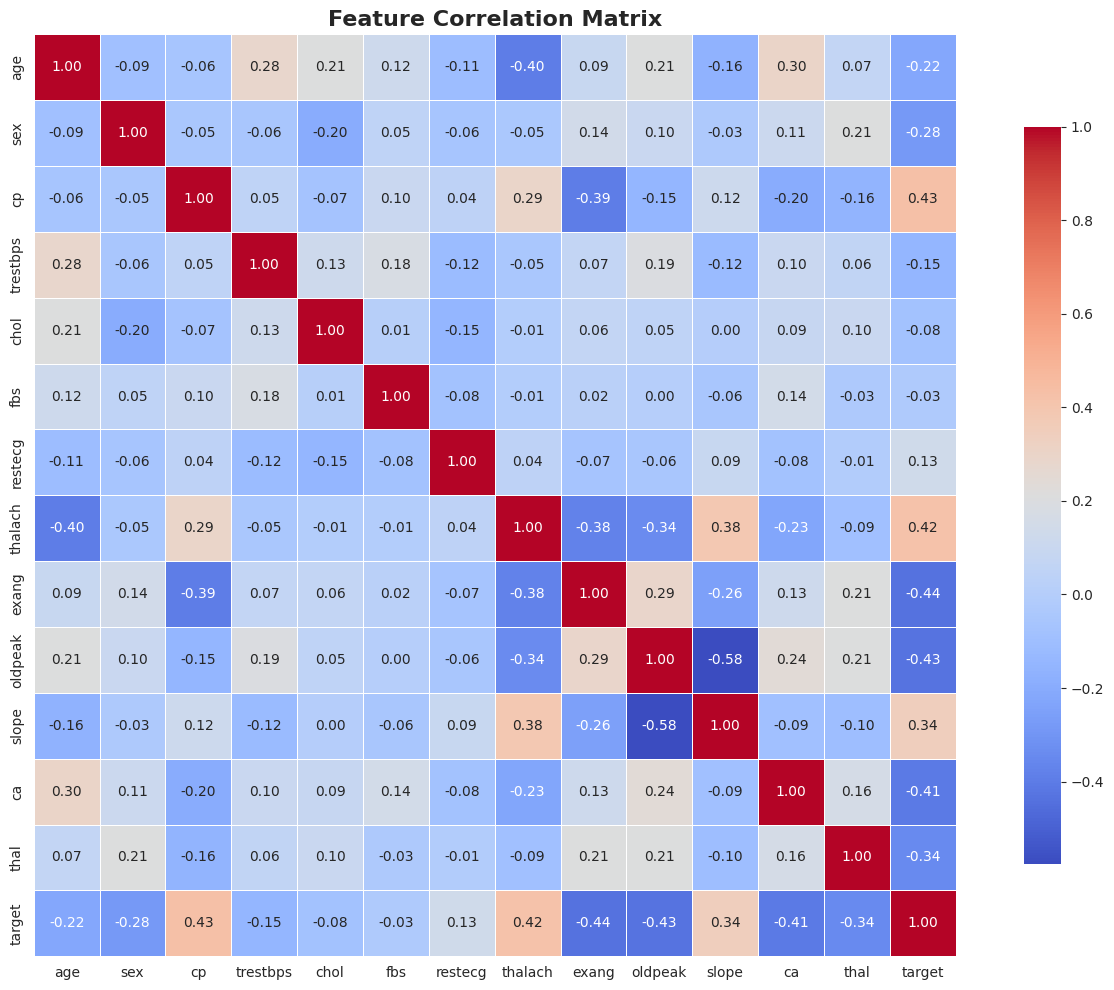

In [9]:
# 6.3 Correlation Matrix
plt.figure(figsize=(14, 10))
correlation = df.corr()
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('images/correlation_matrix.png', dpi=300)
plt.show()

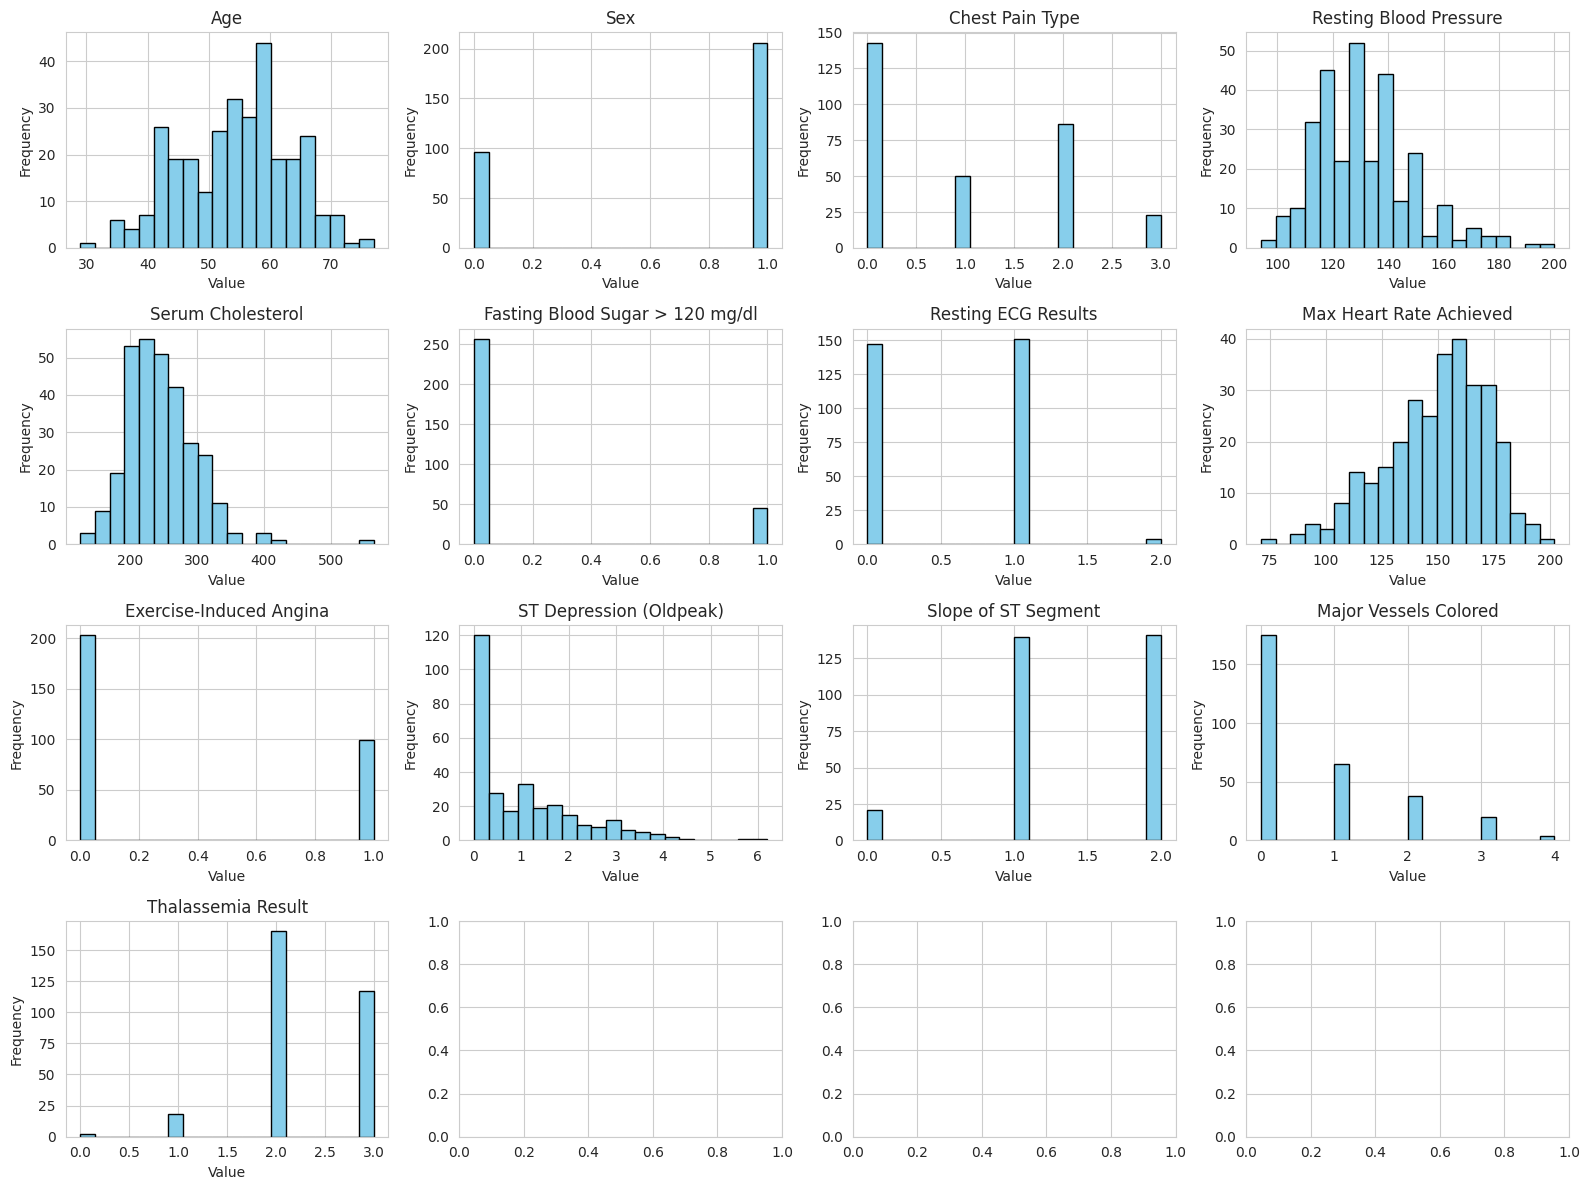

In [10]:
# 6.4 Feature Distributions

feature_names = {
    'age': 'Age',
    'sex': 'Sex',
    'cp': 'Chest Pain Type',
    'trestbps': 'Resting Blood Pressure',
    'chol': 'Serum Cholesterol',
    'fbs': 'Fasting Blood Sugar > 120 mg/dl',
    'restecg': 'Resting ECG Results',
    'thalach': 'Max Heart Rate Achieved',
    'exang': 'Exercise-Induced Angina',
    'oldpeak': 'ST Depression (Oldpeak)',
    'slope': 'Slope of ST Segment',
    'ca': 'Major Vessels Colored',
    'thal': 'Thalassemia Result',
    'target': 'Heart Disease Presence'
}

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
features = df.drop('target', axis=1).columns

for idx, feature in enumerate(features):
    row = idx // 4
    col = idx % 4
    axes[row, col].hist(df[feature], bins=20, color='skyblue', edgecolor='black')
    axes[row, col].set_title(feature_names.get(feature, feature))
    axes[row, col].set_xlabel('Value')
    axes[row, col].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('images/feature_distributions.png', dpi=300)
plt.show()

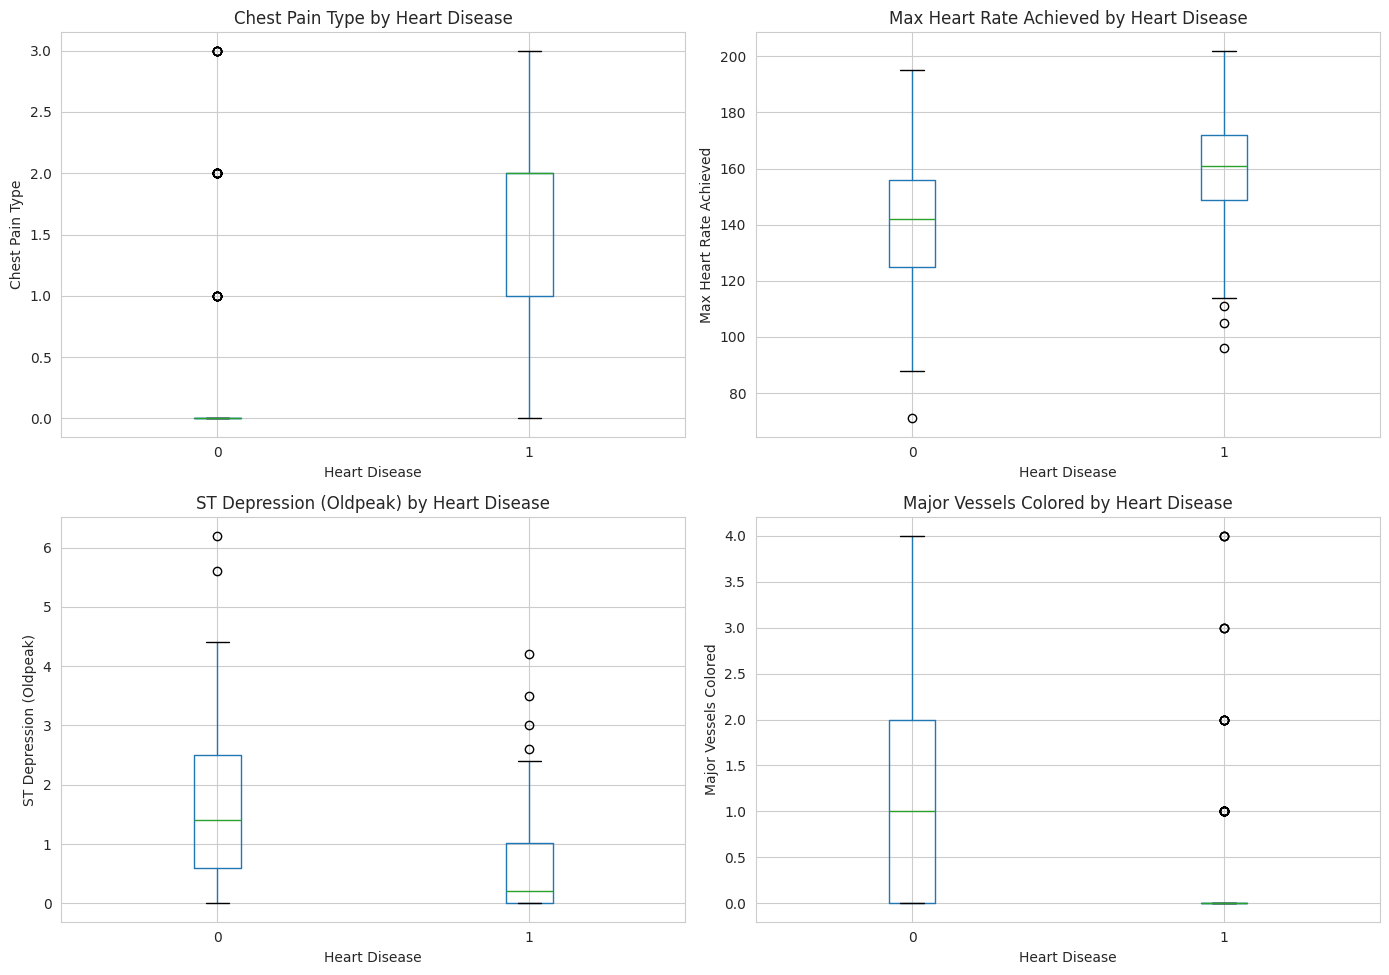

In [11]:
# 6.5 Key Features vs Target
key_features = ['cp', 'thalach', 'oldpeak', 'ca']

feature_names = {
    'cp': 'Chest Pain Type',
    'thalach': 'Max Heart Rate Achieved',
    'oldpeak': 'ST Depression (Oldpeak)',
    'ca': 'Major Vessels Colored'
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for idx, feature in enumerate(key_features):
    row = idx // 2
    col = idx % 2
    df.boxplot(column=feature, by='target', ax=axes[row, col])
    axes[row, col].set_title(f'{feature_names[feature]} by Heart Disease')
    axes[row, col].set_xlabel('Heart Disease')
    axes[row, col].set_ylabel(feature_names[feature])

plt.suptitle('')
plt.tight_layout()
plt.savefig('images/key_features_boxplot.png', dpi=300)
plt.show()

## 5. Train/test split & scaling

A stratified 80/20 split keeps the class balance the same in both sets. The scaler is fit on the training set only to avoid leakage.

In [12]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set: {X_train.shape[0]} patients")
print(f"Test set:     {X_test.shape[0]} patients")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set: 241 patients
Test set:     61 patients


## 6. Baseline models

Four model families: linear (Logistic Regression), ensemble (Random Forest), kernel (SVM) and instance-based (KNN).

In [13]:
# ========================================
# 7. MODEL
# ========================================
print("\n" + "="*50)
print("MODEL PERFORMANCE")
print("="*50)

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42, probability=True),
    'K-Nearest Neighbors': KNeighborsClassifier()
}

# Train models and store results
results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }

    print(f"{name} - Accuracy: {accuracy:.4f}")

print("\n")


MODEL PERFORMANCE
Logistic Regression - Accuracy: 0.8033


Random Forest - Accuracy: 0.7541
SVM - Accuracy: 0.7705
K-Nearest Neighbors - Accuracy: 0.7869




## 7. Hyperparameter tuning (Random Forest)

A 5-fold grid search over 108 combinations.

In [14]:
# ========================================
# 8. HYPERPARAMETER TUNING
# ========================================
print("\n" + "="*50)
print("HYPERPARAMETER TUNING (Random Forest)")
print("="*50)

# Define parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Grid search
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Running GridSearchCV...")
grid_search.fit(X_train_scaled, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

# Train optimized model
best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test_scaled)

# Update results with tuned model
results['Random Forest (Tuned)'] = {
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned),
    'Recall': recall_score(y_test, y_pred_tuned),
    'F1-Score': f1_score(y_test, y_pred_tuned)
}
predictions['Random Forest (Tuned)'] = y_pred_tuned

print(f"\nTuned Random Forest - Accuracy: {results['Random Forest (Tuned)']['Accuracy']:.4f}")


HYPERPARAMETER TUNING (Random Forest)
Running GridSearchCV...
Fitting 5 folds for each of 108 candidates, totalling 540 fits



Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validation score: 0.8505

Tuned Random Forest - Accuracy: 0.7869


## 8. Model comparison


MODEL COMPARISON

                        Accuracy  Precision  Recall  F1-Score
Logistic Regression      0.8033     0.8000  0.8485    0.8235
Random Forest            0.7541     0.7647  0.7879    0.7761
SVM                      0.7705     0.7714  0.8182    0.7941
K-Nearest Neighbors      0.7869     0.7778  0.8485    0.8116
Random Forest (Tuned)    0.7869     0.7941  0.8182    0.8060




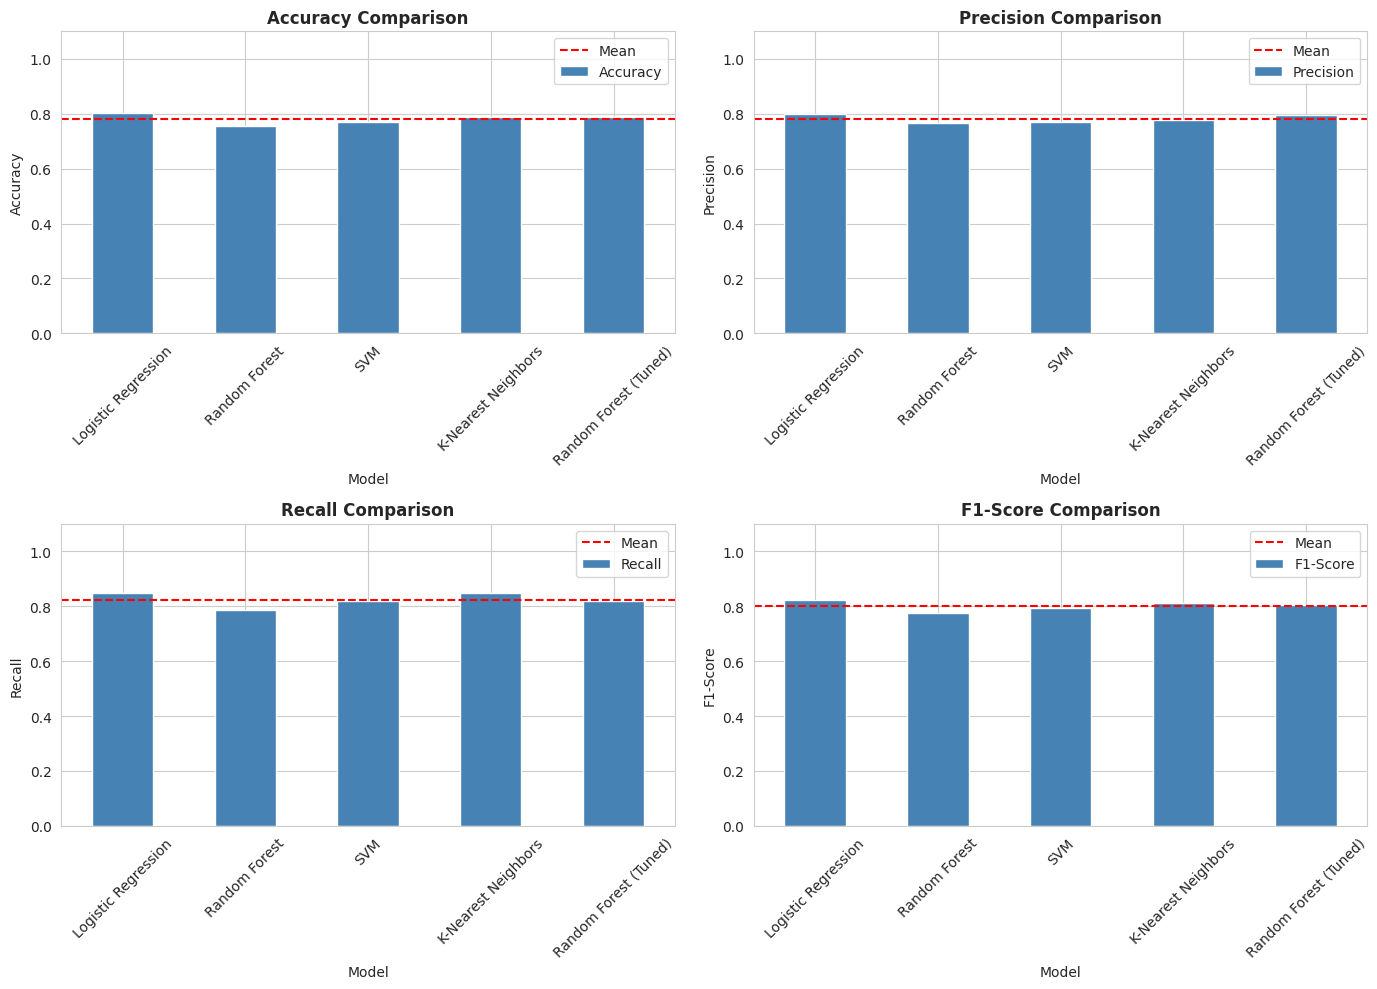

In [15]:
# ========================================
# 9. MODEL COMPARISON
# ========================================
print("\n" + "="*50)
print("MODEL COMPARISON")
print("="*50)

# Create comparison dataframe
comparison_df = pd.DataFrame(results).T
comparison_df = comparison_df.round(4)
print("\n", comparison_df)
print("\n")

# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

for idx, metric in enumerate(metrics):
    row = idx // 2
    col = idx % 2
    comparison_df[metric].plot(kind='bar', ax=axes[row, col], color='steelblue')
    axes[row, col].set_title(f'{metric} Comparison', fontweight='bold')
    axes[row, col].set_ylabel(metric)
    axes[row, col].set_xlabel('Model')
    axes[row, col].set_ylim([0, 1.1])
    axes[row, col].axhline(y=comparison_df[metric].mean(), color='red',
                           linestyle='--', label='Mean')
    axes[row, col].legend()
    axes[row, col].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('images/model_comparison.png', dpi=300)
plt.show()


CONFUSION MATRICES


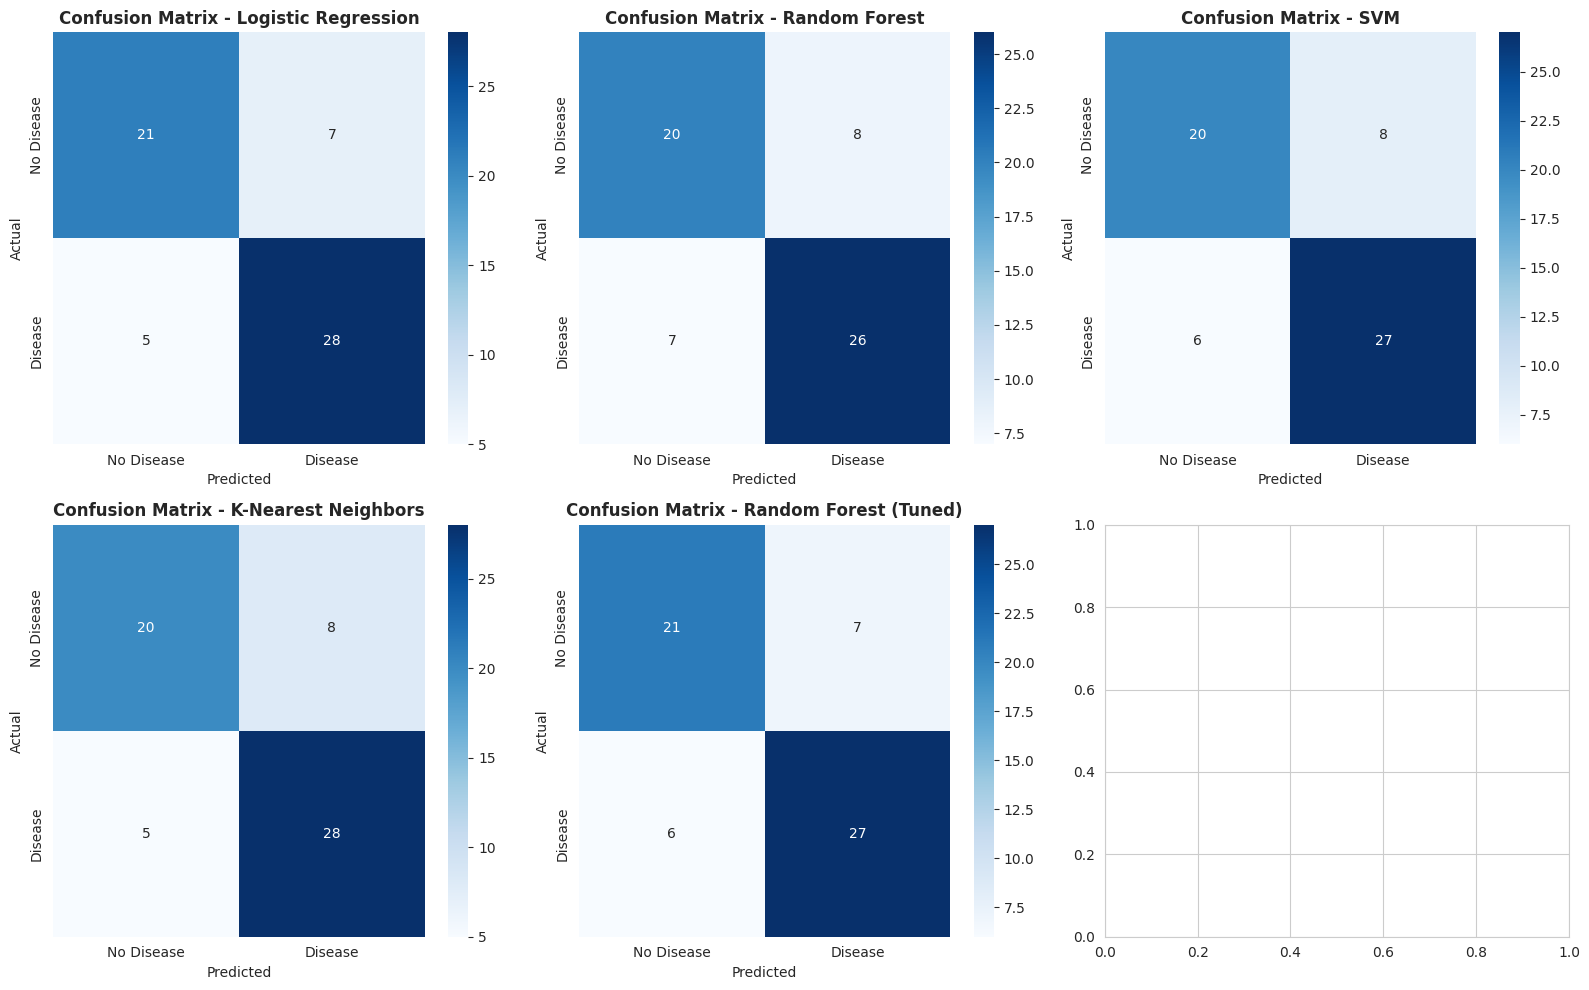

In [16]:
# ========================================
# 10. CONFUSION MATRICES
# ========================================
print("\n" + "="*50)
print("CONFUSION MATRICES")
print("="*50)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['No Disease', 'Disease'],
                yticklabels=['No Disease', 'Disease'])
    axes[idx].set_title(f'Confusion Matrix - {name}', fontweight='bold')
    axes[idx].set_ylabel('Actual')
    axes[idx].set_xlabel('Predicted')

plt.tight_layout()
plt.savefig('images/confusion_matrices.png', dpi=300)
plt.show()

## 9. ROC curves


ROC-AUC ANALYSIS
Logistic Regression - AUC: 0.8712
Random Forest - AUC: 0.8588
SVM - AUC: 0.8420
K-Nearest Neighbors - AUC: 0.8377
Random Forest (Tuned) - AUC: 0.8636




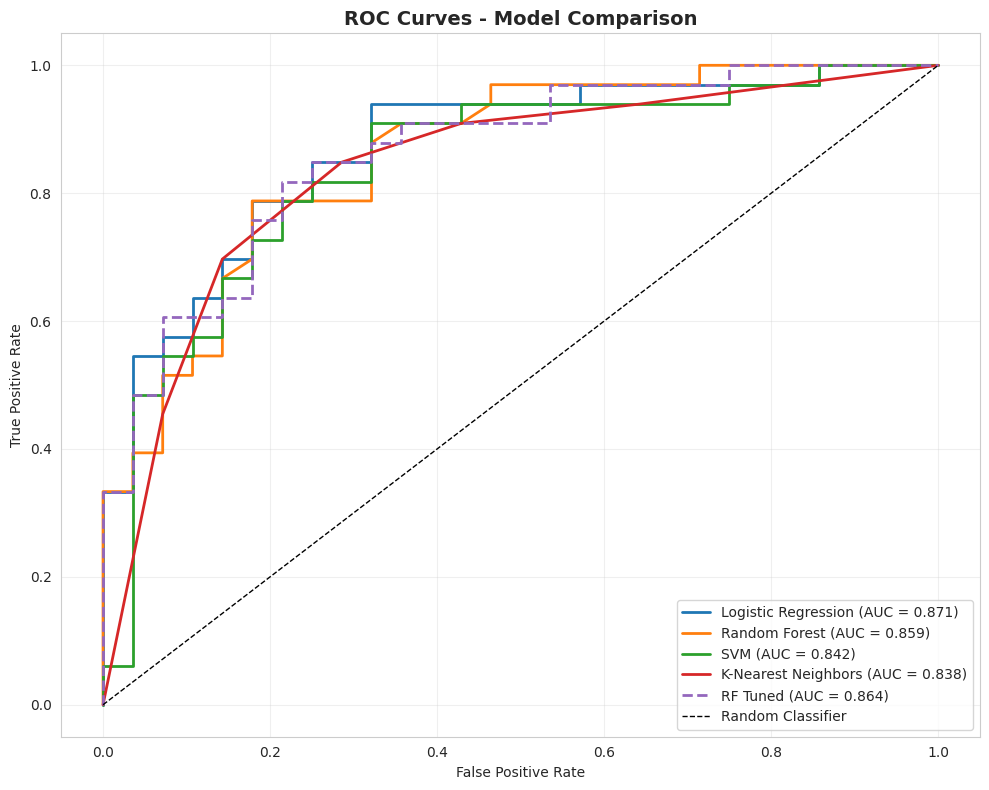

In [17]:
# ========================================
# 11. ROC CURVES
# ========================================
print("\n" + "="*50)
print("ROC-AUC ANALYSIS")
print("="*50)

plt.figure(figsize=(10, 8))

for name, model in models.items():
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', linewidth=2)
        print(f"{name} - AUC: {auc:.4f}")

# Tuned Random Forest
y_proba_tuned = best_rf.predict_proba(X_test_scaled)[:, 1]
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_proba_tuned)
auc_tuned = roc_auc_score(y_test, y_proba_tuned)
plt.plot(fpr_tuned, tpr_tuned, label=f'RF Tuned (AUC = {auc_tuned:.3f})',
         linewidth=2, linestyle='--')
print(f"Random Forest (Tuned) - AUC: {auc_tuned:.4f}")
print("\n")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison', fontweight='bold', fontsize=14)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/roc_curves.png', dpi=300)
plt.show()

## 10. Feature importance


FEATURE IMPORTANCE ANALYSIS

      Feature  Importance
2         cp    0.209821
7    thalach    0.136429
11        ca    0.125787
12      thal    0.110777
9    oldpeak    0.097743
8      exang    0.095344
0        age    0.057449
4       chol    0.044729
1        sex    0.038671
3   trestbps    0.033429
10     slope    0.028893
6    restecg    0.013796
5        fbs    0.007132




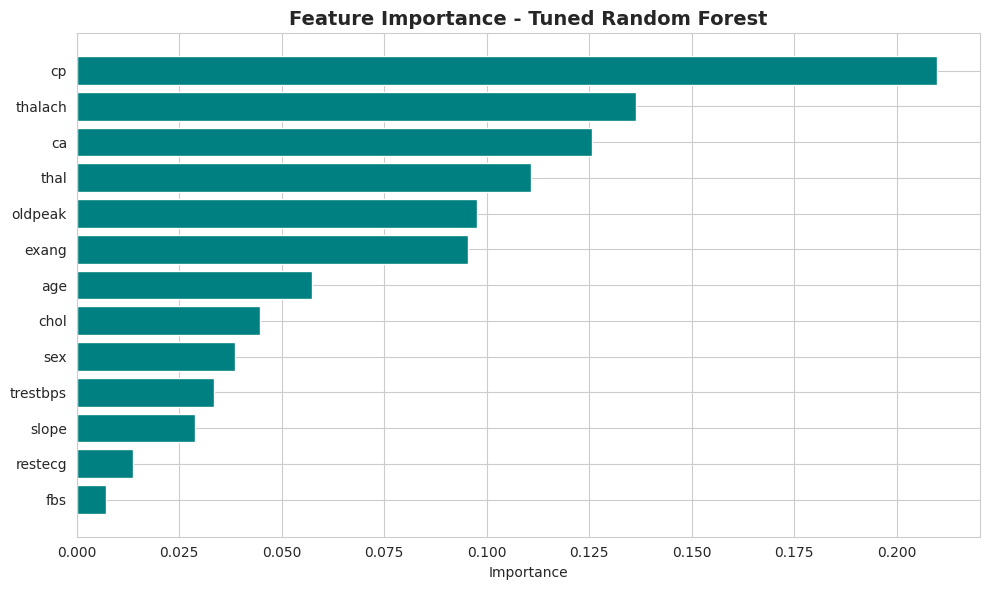

In [18]:
# ========================================
# 12. FEATURE IMPORTANCE (Random Forest)
# ========================================
print("\n" + "="*50)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*50)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n", feature_importance)
print("\n")

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='teal')
plt.xlabel('Importance')
plt.title('Feature Importance - Tuned Random Forest', fontweight='bold', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('images/feature_importance.png', dpi=300)
plt.show()

## 11. Summary

In [19]:
# ========================================
# 13. SUMMARY
# ========================================
print("\n" + "="*50)
print("RESULTS SUMMARY")
print("="*50)

best_model_name = comparison_df['Accuracy'].idxmax()
best_accuracy = comparison_df['Accuracy'].max()

print(f"BEST MODEL: {best_model_name}")
print(f"Accuracy: {best_accuracy:.4f}")
print(f"Precision: {comparison_df.loc[best_model_name, 'Precision']:.4f}")
print(f"Recall: {comparison_df.loc[best_model_name, 'Recall']:.4f}")
print(f"F1-Score: {comparison_df.loc[best_model_name, 'F1-Score']:.4f}")

print("\n" + "="*50)
print("CLASSIFICATION REPORT")
print("="*50)
print(f"\n{best_model_name}:")
print(classification_report(y_test, predictions[best_model_name],
                          target_names=['No Disease', 'Disease']))



RESULTS SUMMARY
BEST MODEL: Logistic Regression
Accuracy: 0.8033
Precision: 0.8000
Recall: 0.8485
F1-Score: 0.8235

CLASSIFICATION REPORT

Logistic Regression:
              precision    recall  f1-score   support

  No Disease       0.81      0.75      0.78        28
     Disease       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



## Conclusions

- **Data quality first:** with duplicates left in, 202 of 205 test rows also appear in the training set and a Random Forest scores a misleading **100%**. The honest accuracy on unique patients is about 80%.
- **Best model: Logistic Regression**, with accuracy 0.80, recall 0.85 on the disease class, F1 0.82 and ROC-AUC 0.87. The simplest model wins on a small dataset of 302 patients and is also the easiest to explain to clinicians.
- The tuned Random Forest reaches 0.85 in cross-validation but 0.79 on the test set. With only 61 test patients, a single test split is noisy, so the CV score is the more stable estimate.
- The most informative features are chest-pain type, number of major vessels (`ca`), thalassemia result, ST depression and max heart rate, which is clinically plausible.
- **Next steps:** repeated stratified CV for tighter estimates, probability calibration, and threshold tuning to trade precision for higher recall.